In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sympy as sp
from matplotlib.ticker import *
import plotly.graph_objects as go
import plotly.subplots as sp
import plotly.express as px
import pycountry_convert as pc
from dash import Dash, dcc, html, Input, Output
from jupyter_dash import JupyterDash
from sklearn.model_selection import train_test_split
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score,LeaveOneOut
from sklearn.linear_model import LinearRegression
from sklearn import metrics
from sklearn import preprocessing

In [2]:
data = pd.read_csv(r"D:\Python\Data\cardata.csv")
df = pd.DataFrame(data)

In [3]:
df.sample(5)

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
229,i20,2012,3.10,6.79,52132,Diesel,Dealer,Manual,0
16,ertiga,2015,7.25,10.79,41678,Diesel,Dealer,Manual,0
185,Suzuki Access 125,2008,0.25,0.58,1900,Petrol,Individual,Automatic,0
256,city,2016,10.25,13.60,49562,Petrol,Dealer,Manual,0
166,Hero Passion Pro,2016,0.45,0.55,1000,Petrol,Individual,Manual,0


In [4]:
df[df.duplicated(keep=False)]

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
15,ertiga,2016,7.75,10.79,43000,Diesel,Dealer,Manual,0
17,ertiga,2016,7.75,10.79,43000,Diesel,Dealer,Manual,0
51,fortuner,2015,23.00,30.61,40000,Diesel,Dealer,Automatic,0
93,fortuner,2015,23.00,30.61,40000,Diesel,Dealer,Automatic,0


In [5]:
df.describe(include="all") # no missing values

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
count,301,301.000000,301.000000,301.000000,301.000000,301,301,301,301.000000
unique,98,NaN,NaN,NaN,NaN,3,2,2,NaN
top,city,NaN,NaN,NaN,NaN,Petrol,Dealer,Manual,NaN
freq,26,NaN,NaN,NaN,NaN,239,195,261,NaN
mean,NaN,2013.627907,4.661296,7.628472,36947.205980,NaN,NaN,NaN,0.043189
std,NaN,2.891554,5.082812,8.644115,38886.883882,NaN,NaN,NaN,0.247915
min,NaN,2003.000000,0.100000,0.320000,500.000000,NaN,NaN,NaN,0.000000
25%,NaN,2012.000000,0.900000,1.200000,15000.000000,NaN,NaN,NaN,0.000000
50%,NaN,2014.000000,3.600000,6.400000,32000.000000,NaN,NaN,NaN,0.000000
75%,NaN,2016.000000,6.000000,9.900000,48767.000000,NaN,NaN,NaN,0.000000


In [6]:
df = df.drop(columns="Car_Name")

In [7]:
# let's change Year to Age based on MAX of Year+1
df.insert(1,"Age",df["Year"].max()+1-df["Year"])

In [8]:
df.drop(columns="Year",inplace=True)

In [9]:
df.sample(5)

,Age,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
37,16,0.35,2.28,127000,Petrol,Individual,Manual,0
178,5,0.35,0.52,19000,Petrol,Individual,Automatic,0
234,4,5.50,5.70,4492,Petrol,Dealer,Manual,0
92,14,3.51,13.70,75000,Petrol,Dealer,Manual,0
99,9,9.65,20.45,50024,Diesel,Dealer,Manual,0


<div style="border-radius:10px; padding: 10px; background-color: #C1E1C1; font-size:115%; text-align:left">
<font color=black>We have 4 catergorical columns, let's see number of unique values for each of them.

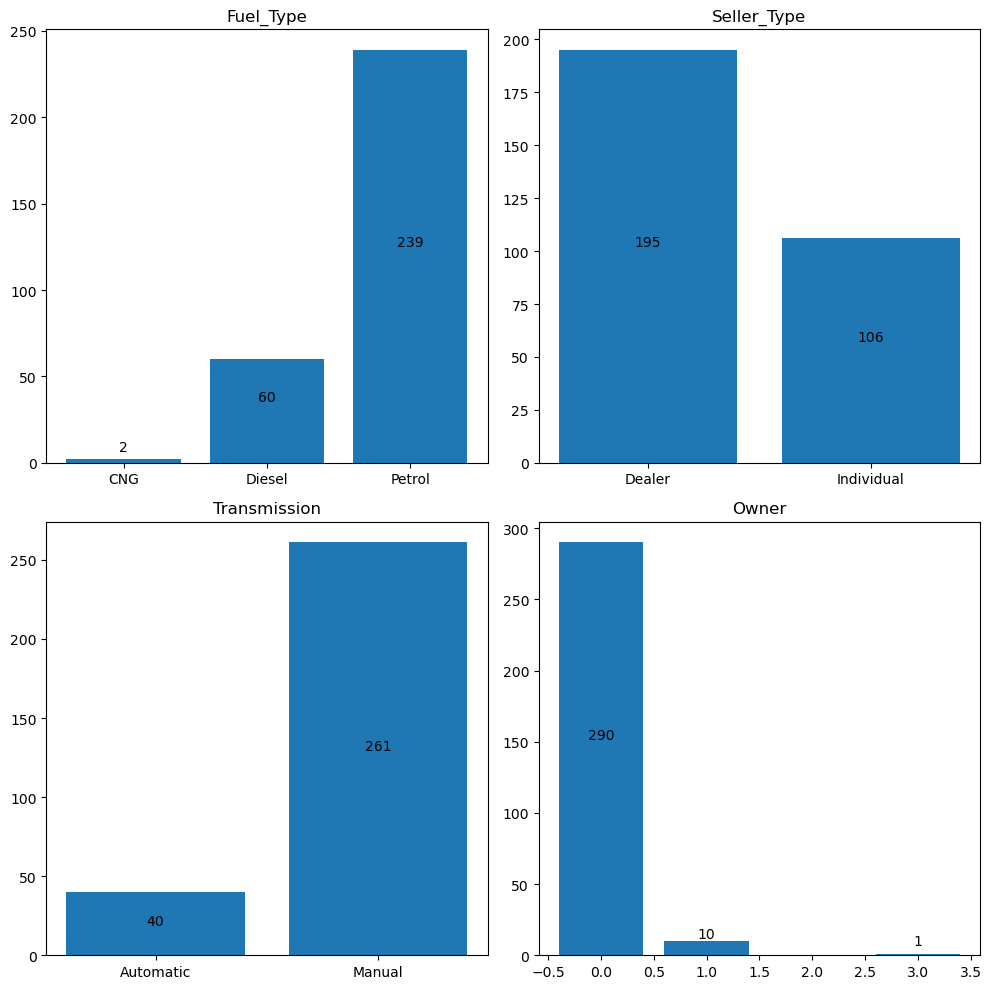

In [10]:
fig, ax = plt.subplots(2,2,sharex=False, figsize=(10, 10))

ax[0][0].bar_label(ax[0][0].bar(df.groupby(["Fuel_Type"])["Age"].count().reset_index()["Fuel_Type"], df.groupby(["Fuel_Type"])["Age"].count().reset_index()["Age"]),label_type="center",padding=10)
ax[0][0].set_title("Fuel_Type")
ax[0][1].bar_label(ax[0][1].bar(df.groupby(["Seller_Type"])["Age"].count().reset_index()["Seller_Type"], df.groupby(["Seller_Type"])["Age"].count().reset_index()["Age"]),label_type="center",padding=10)
ax[0][1].set_title("Seller_Type")
ax[1][0].bar_label(ax[1][0].bar(df.groupby(["Transmission"])["Age"].count().reset_index()["Transmission"], df.groupby(["Transmission"])["Age"].count().reset_index()["Age"]),label_type="center",padding=2);
ax[1][0].set_title("Transmission")
ax[1][1].bar_label(ax[1][1].bar(df.groupby(["Owner"])["Age"].count().reset_index()["Owner"], df.groupby(["Owner"])["Age"].count().reset_index()["Age"]),label_type="center",padding=10);
ax[1][1].set_title("Owner")
fig.tight_layout()

In [11]:
df[df["Fuel_Type"]=="CNG"]

,Age,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
18,4,3.25,5.09,35500,CNG,Dealer,Manual,0
35,8,2.95,7.74,49998,CNG,Dealer,Manual,0


In [12]:
dfnu =  df.drop(columns="Selling_Price")
dfnu["Selling_Price"] = df["Selling_Price"]
dfnu.sample(5)

,Age,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner,Selling_Price
82,2,25.39,15000,Diesel,Dealer,Automatic,0,23.00
244,6,9.40,49000,Diesel,Dealer,Manual,0,5.95
84,14,13.46,197176,Diesel,Dealer,Manual,0,3.49
294,5,6.80,33019,Petrol,Dealer,Manual,0,3.75
35,8,7.74,49998,CNG,Dealer,Manual,0,2.95


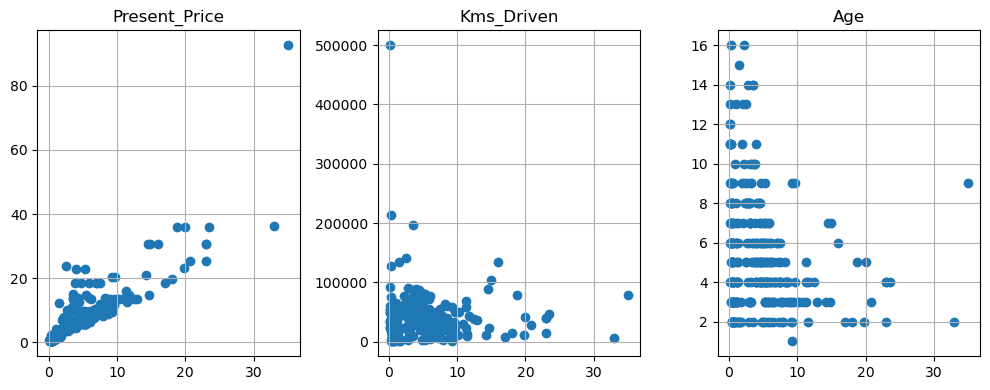

In [13]:
fig, axs = plt.subplots(1,3,sharex=False, figsize=(10, 4))
axs[0].scatter(dfnu["Selling_Price"],dfnu["Present_Price"])
axs[0].grid();axs[0].set_title("Present_Price")
axs[1].scatter(dfnu["Selling_Price"],dfnu["Kms_Driven"])
axs[1].grid();axs[1].set_title("Kms_Driven")
axs[2].scatter(dfnu["Selling_Price"],dfnu["Age"])
axs[2].grid();axs[2].set_title("Age")
fig.tight_layout()

<div style="border-radius:10px; padding: 10px; background-color: #C1E1C1; font-size:115%; text-align:left">
<font color=black>let's remove all Selling price more than 30 and Kms driven more than 400k,because these three records are remote and may affect our model.

In [14]:
dfnu[(dfnu["Selling_Price"]>30) | (dfnu["Kms_Driven"]>400000)]

,Age,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner,Selling_Price
64,2,36.23,6000,Diesel,Dealer,Automatic,0,33.00
86,9,92.60,78000,Diesel,Dealer,Manual,0,35.00
196,11,0.52,500000,Petrol,Individual,Automatic,0,0.17


In [15]:
dfnu = dfnu.drop([64,86,196]).reset_index().drop(columns="index")

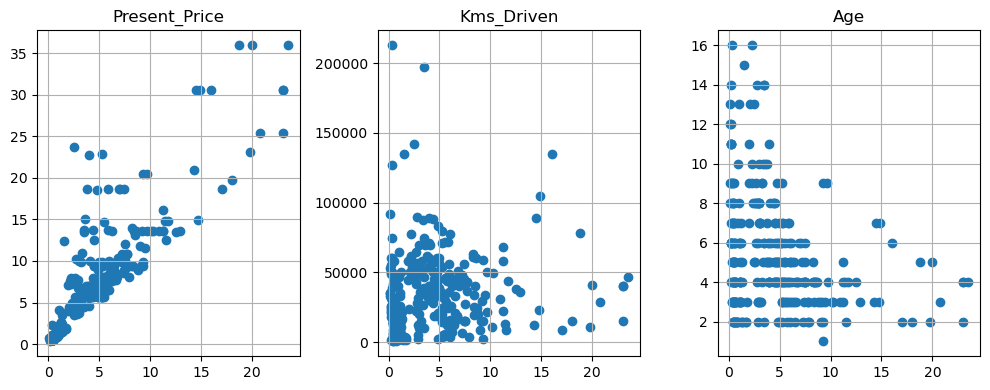

In [16]:
fig, axs = plt.subplots(1,3,sharex=False, figsize=(10, 4))
axs[0].scatter(dfnu["Selling_Price"],dfnu["Present_Price"])
axs[0].grid();axs[0].set_title("Present_Price")
axs[1].scatter(dfnu["Selling_Price"],dfnu["Kms_Driven"])
axs[1].grid();axs[1].set_title("Kms_Driven")
axs[2].scatter(dfnu["Selling_Price"],dfnu["Age"])
axs[2].grid();axs[2].set_title("Age")
fig.tight_layout()

<div style="border-radius:10px; padding: 10px; background-color: #C1E1C1; font-size:115%; text-align:left">
<font color=black>converting catergories to numbers

In [17]:
dfnu["Fuel_Type"] = dfnu["Fuel_Type"].replace(["CNG","Petrol","Diesel"], [4.0,3.0,2.0])
dfnu["Seller_Type"] = dfnu["Seller_Type"].replace(["Dealer","Individual"], [3.0,2.0])
dfnu["Transmission"] = dfnu["Transmission"].replace(["Automatic","Manual"], [3.0,2.0])

dfnu.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 298 entries, 0 to 297
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Age            298 non-null    int64  
 1   Present_Price  298 non-null    float64
 2   Kms_Driven     298 non-null    int64  
 3   Fuel_Type      298 non-null    float64
 4   Seller_Type    298 non-null    float64
 5   Transmission   298 non-null    float64
 6   Owner          298 non-null    int64  
 7   Selling_Price  298 non-null    float64
dtypes: float64(5), int64(3)
memory usage: 18.8 KB


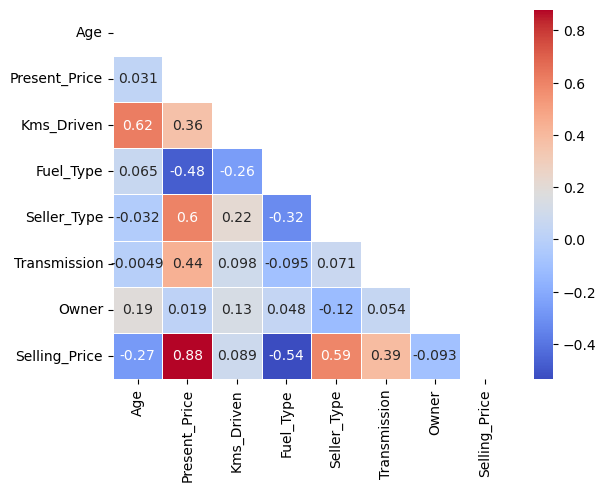

In [18]:
sns.heatmap(dfnu.corr(), annot=True,linewidth=.5,cmap="coolwarm",mask=np.triu(dfnu.corr()));

In [19]:
kfv = KFold(5)
ts = 0.2
resultcv = pd.DataFrame()

<a id="datades"></a>
<p style="background-color:#4F7942; font-family:roboto; color:white; font-size:145%;font-weight:bold; text-align:center; border-radius:25px 10px; padding: 10px">1 - Model = A(x1)+B(x2)+C(x3)+D(x4)+E(x5)+F(x6)+G(x7) </p>

In [20]:
dfn = dfnu.copy()

In [21]:
dfn.describe()

,Age,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner,Selling_Price
count,298.000000,298.000000,298.000000,298.000000,298.000000,298.000000,298.000000,298.000000
mean,5.352349,7.271208,35359.426174,2.812081,2.647651,2.127517,0.043624,4.479463
std,2.873309,6.936325,28179.600676,0.408151,0.478506,0.334112,0.249126,4.493523
min,1.000000,0.320000,500.000000,2.000000,2.000000,2.000000,0.000000,0.100000
25%,3.000000,1.215000,15000.000000,3.000000,2.000000,2.000000,0.000000,0.900000
50%,5.000000,6.250000,32000.000000,3.000000,3.000000,2.000000,0.000000,3.555000
75%,7.000000,9.845000,47750.000000,3.000000,3.000000,2.000000,0.000000,6.000000
max,16.000000,35.960000,213000.000000,4.000000,3.000000,3.000000,3.000000,23.500000


<a id="basic"></a>
<p style="background-color:#6C935C; font-family:roboto; color:white; font-size:115%; text-align:center;border-radius:25px 10px; padding:5px">1.1 -<span style="color:white;font-weight:bold"> Scaling

In [22]:
scaler = preprocessing.MinMaxScaler(feature_range=(0,1))

N = scaler.fit_transform(dfn.drop(columns="Selling_Price"))
dfw = pd.DataFrame(N,columns = list(dfn.drop(columns="Selling_Price").columns))
dfw["Selling_Price"] = dfn["Selling_Price"]

<a id="basic"></a>
<p style="background-color:#6C935C; font-family:roboto; color:white; font-size:115%; text-align:center;border-radius:25px 10px; padding:5px">1.2 -<span style="color:white;font-weight:bold"> Defining x , y and Modeling

In [23]:
x=dfw.drop(columns="Selling_Price")
y=dfw["Selling_Price"].values.reshape(-1,1)
x_train, x_test, y_train, y_test=train_test_split(x,y, test_size=ts,random_state=0)

model_n = LinearRegression()
regressor = LinearRegression()

<a id="basic"></a>
<p style="background-color:#6C935C; font-family:roboto; color:white; font-size:115%; text-align:center;border-radius:25px 10px; padding:5px">1.3 -<span style="color:white;font-weight:bold"> KFold Test and Evaluation

In [24]:
results = cross_val_score(regressor,x,y,cv=kfv)
regressor.fit(x_train,y_train)
resultcv.insert(0,"M",np.append(results,[(np.mean(results)),regressor.score(x,y),regressor.score(x_test,y_test)]))

regressor.score(x,y)

0.8885392802515558

<a id="datades"></a>
<p style="background-color:#4F7942; font-family:roboto; color:white; font-size:145%;font-weight:bold; text-align:center; border-radius:25px 10px; padding: 10px">2 - Model 1 = A(x1)+B(x2)+C(x3)+D(x4)+E(x5)+F(x6)+G(x7)+H(x4)/(x1) </p>

<a id="basic"></a>
<p style="background-color:#6C935C; font-family:roboto; color:white; font-size:115%; text-align:center;border-radius:25px 10px; padding:5px">2.1 -<span style="color:white;font-weight:bold"> Scaling

In [25]:
dfn1 = dfn.copy()
dfn1.insert(7,"Kms/Age",dfn1["Kms_Driven"]/dfn1["Age"])

In [26]:
N2 = scaler.fit_transform(dfn1.drop(columns="Selling_Price"))
dfw1 = pd.DataFrame(N2,columns = list(dfn1.drop(columns="Selling_Price").columns))
dfw1["Selling_Price"] = dfn1["Selling_Price"]

<a id="basic"></a>
<p style="background-color:#6C935C; font-family:roboto; color:white; font-size:115%; text-align:center;border-radius:25px 10px; padding:5px">2.2 -<span style="color:white;font-weight:bold"> Defining x , y and Modeling

In [27]:
x1=dfw1.drop(columns="Selling_Price")
y1=dfw1["Selling_Price"].values.reshape(-1,1)
x_train1, x_test1, y_train1, y_test1=train_test_split(x1,y1, test_size=ts,random_state=0)

model_n = LinearRegression()
regressor = LinearRegression()

<a id="basic"></a>
<p style="background-color:#6C935C; font-family:roboto; color:white; font-size:115%; text-align:center;border-radius:25px 10px; padding:5px">2.3 -<span style="color:white;font-weight:bold"> KFold Test and Evaluation

In [28]:
results = cross_val_score(model_n,x1,y1,cv=kfv)
regressor.fit(x_train1,y_train1)
resultcv.insert(0,"M1[(x4)/(x1)]",np.append(results,[(np.mean(results)),regressor.score(x1,y1),regressor.score(x_test1,y_test1)]))

<a id="datades"></a>
<p style="background-color:#4F7942; font-family:roboto; color:white; font-size:145%;font-weight:bold; text-align:center; border-radius:25px 10px; padding: 10px">3 - Model 2 = A(x1)+B(x2)+C(x3)+D(x4)+E(x5)+F(x6)+G(x7)+H(x4)/(x1)+I(x1^-1) </p>

In [29]:
dfn2 = dfn1.copy()
dfn2.insert(7,"Age^-1",dfn2["Age"].astype("float64")**(-1))

<a id="basic"></a>
<p style="background-color:#6C935C; font-family:roboto; color:white; font-size:115%; text-align:center;border-radius:25px 10px; padding:5px">3.1 -<span style="color:white;font-weight:bold"> Scaling

In [30]:
N3 = scaler.fit_transform(dfn2.drop(columns="Selling_Price"))
dfw2 = pd.DataFrame(N3,columns = list(dfn2.drop(columns="Selling_Price").columns))
dfw2["Selling_Price"] = dfn2["Selling_Price"]

<a id="basic"></a>
<p style="background-color:#6C935C; font-family:roboto; color:white; font-size:115%; text-align:center;border-radius:25px 10px; padding:5px">3.2 -<span style="color:white;font-weight:bold"> Defining x , y and Modeling

In [31]:
x2=dfw2.drop(columns="Selling_Price")
y2=dfw2["Selling_Price"].values.reshape(-1,1)
x_train2, x_test2, y_train2, y_test2=train_test_split(x2,y2, test_size=ts,random_state=0)

model_n = LinearRegression()
regressor = LinearRegression()

<a id="basic"></a>
<p style="background-color:#6C935C; font-family:roboto; color:white; font-size:115%; text-align:center;border-radius:25px 10px; padding:5px">3.3 -<span style="color:white;font-weight:bold"> KFold Test and Evaluation

In [32]:
results = cross_val_score(model_n,x2,y2,cv=kfv)
regressor.fit(x_train2,y_train2)
resultcv.insert(0,"M2[(x4)/(x1)+(x1^-1)]",np.append(results,[(np.mean(results)),regressor.score(x2,y2),regressor.score(x_test2,y_test2)]))
#end

<a id="datades"></a>
<p style="background-color:#4F7942; font-family:roboto; color:white; font-size:145%;font-weight:bold; text-align:center; border-radius:25px 10px; padding: 10px">4 - Model 3 = A(x1)+B(x2)+C(x3)+D(x4)+E(x5)+F(x6)+G(x7)+H(x1^-1) </p>

In [33]:
dfn3 = dfn.copy()
dfn3.insert(7,"Age^-1",dfn3["Age"].astype("float64")**(-1))

<a id="basic"></a>
<p style="background-color:#6C935C; font-family:roboto; color:white; font-size:115%; text-align:center;border-radius:25px 10px; padding:5px">4.1 -<span style="color:white;font-weight:bold"> Scaling

In [34]:
N4 = scaler.fit_transform(dfn3.drop(columns="Selling_Price"))
dfw3 = pd.DataFrame(N4,columns = list(dfn3.drop(columns="Selling_Price").columns))
dfw3["Selling_Price"] = dfn3["Selling_Price"]

<a id="basic"></a>
<p style="background-color:#6C935C; font-family:roboto; color:white; font-size:115%; text-align:center;border-radius:25px 10px; padding:5px">4.2 -<span style="color:white;font-weight:bold"> Defining x , y and Modeling

In [35]:
x3=dfw3.iloc[:,:8]
y3=dfw3["Selling_Price"].values.reshape(-1,1)
x_train3, x_test3, y_train3, y_test3=train_test_split(x3,y3, test_size=ts,random_state=0)

model_n = LinearRegression()
regressor = LinearRegression()

<a id="basic"></a>
<p style="background-color:#6C935C; font-family:roboto; color:white; font-size:115%; text-align:center;border-radius:25px 10px; padding:5px">4.3 -<span style="color:white;font-weight:bold"> KFold Test and Evaluation

In [36]:
results = cross_val_score(model_n,x3,y3,cv=kfv)
regressor.fit(x_train3,y_train3)
resultcv.insert(0,"M3[(x1^-1)]",np.append(results,[(np.mean(results)),regressor.score(x3,y3),regressor.score(x_test3,y_test3)]))

<a id="datades"></a>
<p style="background-color:#4F7942; font-family:roboto; color:white; font-size:145%;font-weight:bold; text-align:center; border-radius:25px 10px; padding: 10px">5 - Model 4 = A(x1)+B(x2)+C(x3)+D(x4)+E(x5)+F(x6)+G(x7)+H(x4)/(x1)+I(x1^-1)+J(x2^2) </p>

In [37]:
dfn4 = dfn2.copy()
dfn4.insert(7,"Present_Price^2",dfn4["Present_Price"].astype("float64")**(2))

<a id="basic"></a>
<p style="background-color:#6C935C; font-family:roboto; color:white; font-size:115%; text-align:center;border-radius:25px 10px; padding:5px">5.1 -<span style="color:white;font-weight:bold"> Scaling

In [38]:
N5 = scaler.fit_transform(dfn4.drop(columns="Selling_Price"))
dfw4 = pd.DataFrame(N5,columns = list(dfn4.drop(columns="Selling_Price").columns))
dfw4["Selling_Price"] = dfn4["Selling_Price"]

<a id="basic"></a>
<p style="background-color:#6C935C; font-family:roboto; color:white; font-size:115%; text-align:center;border-radius:25px 10px; padding:5px">5.2 -<span style="color:white;font-weight:bold"> Defining x , y and Modeling

In [39]:
x4=dfw4.drop(columns="Selling_Price")
y4=dfw4["Selling_Price"].values.reshape(-1,1)
x_train4, x_test4, y_train4, y_test4=train_test_split(x4,y4, test_size=ts,random_state=0)

model_n = LinearRegression()
regressor = LinearRegression()

<a id="basic"></a>
<p style="background-color:#6C935C; font-family:roboto; color:white; font-size:115%; text-align:center;border-radius:25px 10px; padding:5px">5.3 -<span style="color:white;font-weight:bold"> KFold Test and Evaluation

In [40]:
results = cross_val_score(model_n,x4,y4,cv=kfv)
regressor.fit(x_train4,y_train4)
resultcv.insert(0,"M4[(x4)/(x1)+(x1^-1)+(x2^2)]",np.append(results,[(np.mean(results)),regressor.score(x4,y4),regressor.score(x_test4,y_test4)]))

<a id="datades"></a>
<p style="background-color:#4F7942; font-family:roboto; color:white; font-size:145%;font-weight:bold; text-align:center; border-radius:25px 10px; padding: 10px">6 - Model 5 = A(x1)+B(x2)+C(x3)+D(x4)+E(x5)+F(x6)+G(x7)+H(x4)/(x1)+I(x2^2) </p>

In [41]:
dfn5 = dfn1.copy()
dfn5.insert(7,"Present_Price^2",dfn5["Present_Price"].astype("float64")**(2))

<a id="basic"></a>
<p style="background-color:#6C935C; font-family:roboto; color:white; font-size:115%; text-align:center;border-radius:25px 10px; padding:5px">6.1 -<span style="color:white;font-weight:bold"> Scaling

In [42]:
N6 = scaler.fit_transform(dfn5.drop(columns="Selling_Price"))
dfw5 = pd.DataFrame(N6,columns = list(dfn5.drop(columns="Selling_Price").columns))
dfw5["Selling_Price"] = dfn5["Selling_Price"]

<a id="basic"></a>
<p style="background-color:#6C935C; font-family:roboto; color:white; font-size:115%; text-align:center;border-radius:25px 10px; padding:5px">6.2 -<span style="color:white;font-weight:bold"> Defining x , y and Modeling

In [43]:
x5=dfw5.drop(columns="Selling_Price")
y5=dfw5["Selling_Price"].values.reshape(-1,1)
x_train5, x_test5, y_train5, y_test5=train_test_split(x5,y5, test_size=ts,random_state=0)

model_n = LinearRegression()
regressor = LinearRegression()

<a id="basic"></a>
<p style="background-color:#6C935C; font-family:roboto; color:white; font-size:115%; text-align:center;border-radius:25px 10px; padding:5px">6.3 -<span style="color:white;font-weight:bold"> KFold Test and Evaluation

In [44]:
results = cross_val_score(model_n,x5,y5,cv=kfv)
regressor.fit(x_train5,y_train5)
resultcv.insert(0,"M5[(x4)/(x1)+(x2^2)]",np.append(results,[(np.mean(results)),regressor.score(x5,y5),regressor.score(x_test5,y_test5)]))

<a id="datades"></a>
<p style="background-color:#4F7942; font-family:roboto; color:white; font-size:145%;font-weight:bold; text-align:center; border-radius:25px 10px; padding: 10px">7 - Model 6 = A(x1)+B(x2)+C(x3)+D(x4)+E(x5)+F(x6)+G(x7)+H(x4)/(x1)+I(x2^3) </p>

In [45]:
dfn6 = dfn1.copy()
dfn6.insert(7,"Present_Price^3",dfn6["Present_Price"].astype("float64")**(3))

<a id="basic"></a>
<p style="background-color:#6C935C; font-family:roboto; color:white; font-size:115%; text-align:center;border-radius:25px 10px; padding:5px">7.1 -<span style="color:white;font-weight:bold"> Scaling

In [46]:
N7 = scaler.fit_transform(dfn6.drop(columns="Selling_Price"))
dfw6 = pd.DataFrame(N7,columns = list(dfn6.drop(columns="Selling_Price").columns))
dfw6["Selling_Price"] = dfn6["Selling_Price"]

<a id="basic"></a>
<p style="background-color:#6C935C; font-family:roboto; color:white; font-size:115%; text-align:center;border-radius:25px 10px; padding:5px">7.2 -<span style="color:white;font-weight:bold"> Defining x , y and Modeling

In [47]:
x6=dfw6.drop(columns="Selling_Price")
y6=dfw6["Selling_Price"].values.reshape(-1,1)
x_train6, x_test6, y_train6, y_test6=train_test_split(x6,y6, test_size=ts,random_state=0)

model_n = LinearRegression()
regressor = LinearRegression()

<a id="basic"></a>
<p style="background-color:#6C935C; font-family:roboto; color:white; font-size:115%; text-align:center;border-radius:25px 10px; padding:5px">7.3 -<span style="color:white;font-weight:bold"> KFold Test and Evaluation

In [48]:
results = cross_val_score(model_n,x6,y6,cv=kfv)
regressor.fit(x_train6,y_train6)
resultcv.insert(0,"M6[(x4)/(x1)+(x2^3)]",np.append(results,[(np.mean(results)),regressor.score(x6,y6),regressor.score(x_test6,y_test6)]))

<a id="datades"></a>
<p style="background-color:#4F7942; font-family:roboto; color:white; font-size:145%;font-weight:bold; text-align:center; border-radius:25px 10px; padding: 10px">8 - Model 7 = A(x1)+B(x2)+C(x3)+D(x4)+E(x5)+F(x6)+G(x7)+H(x4)/(x1)+I(x4)(x5)(x6) </p>

In [49]:
dfn7 = dfn1.copy()
dfn7.insert(7,"Fue*Sel*Tran",dfn7["Fuel_Type"]*dfn7["Seller_Type"]*dfn7["Transmission"])

<a id="basic"></a>
<p style="background-color:#6C935C; font-family:roboto; color:white; font-size:115%; text-align:center;border-radius:25px 10px; padding:5px">8.1 -<span style="color:white;font-weight:bold"> Scaling

In [50]:
N8 = scaler.fit_transform(dfn7.drop(columns="Selling_Price"))
dfw7 = pd.DataFrame(N8,columns = list(dfn7.drop(columns="Selling_Price").columns))
dfw7["Selling_Price"] = dfn7["Selling_Price"]

<a id="basic"></a>
<p style="background-color:#6C935C; font-family:roboto; color:white; font-size:115%; text-align:center;border-radius:25px 10px; padding:5px">8.2 -<span style="color:white;font-weight:bold"> Defining x , y and Modeling

In [51]:
x7=dfw7.drop(columns="Selling_Price")
y7=dfw7["Selling_Price"].values.reshape(-1,1)
x_train7, x_test7, y_train7, y_test7=train_test_split(x7,y7, test_size=ts,random_state=0)

model_n = LinearRegression()
regressor = LinearRegression()

<a id="basic"></a>
<p style="background-color:#6C935C; font-family:roboto; color:white; font-size:115%; text-align:center;border-radius:25px 10px; padding:5px">8.3 -<span style="color:white;font-weight:bold"> KFold Test and Evaluation

In [52]:
results = cross_val_score(model_n,x7,y7,cv=kfv)
regressor.fit(x_train7,y_train7)
resultcv.insert(0,"M7[(x4)/(x1)+(x4)(x5)(x6)]",np.append(results,[(np.mean(results)),regressor.score(x7,y7),regressor.score(x_test7,y_test7)]))

<a id="datades"></a>
<p style="background-color:#4F7942; font-family:roboto; color:white; font-size:145%;font-weight:bold; text-align:center; border-radius:25px 10px; padding: 10px">9 - Model 8 = A(x1)+B(x2)+C(x3)+D(x4)+E(x5)+F(x6)+G(x7)+H(x4)/(x1)+I(x4)(x5)(x6)+J(x2)(x6) </p>

In [53]:
dfn8 = dfn7.copy()
dfn8.insert(7,"Pres*Trans",dfn8["Present_Price"]*dfn8["Transmission"])

<a id="basic"></a>
<p style="background-color:#6C935C; font-family:roboto; color:white; font-size:115%; text-align:center;border-radius:25px 10px; padding:5px">9.1 -<span style="color:white;font-weight:bold"> Scaling

In [54]:
N9 = scaler.fit_transform(dfn8.drop(columns="Selling_Price"))
dfw8 = pd.DataFrame(N9,columns = list(dfn8.drop(columns="Selling_Price").columns))
dfw8["Selling_Price"] = dfn8["Selling_Price"]

<a id="basic"></a>
<p style="background-color:#6C935C; font-family:roboto; color:white; font-size:115%; text-align:center;border-radius:25px 10px; padding:5px">9.2 -<span style="color:white;font-weight:bold"> Defining x , y and Modeling

In [55]:
x8=dfw8.drop(columns="Selling_Price")
y8=dfw8["Selling_Price"].values.reshape(-1,1)
x_train8, x_test8, y_train8, y_test8=train_test_split(x8,y8, test_size=ts,random_state=0)

model_n = LinearRegression()
regressor = LinearRegression()

<a id="basic"></a>
<p style="background-color:#6C935C; font-family:roboto; color:white; font-size:115%; text-align:center;border-radius:25px 10px; padding:5px">9.3 -<span style="color:white;font-weight:bold"> KFold Test and Evaluation

In [56]:
results = cross_val_score(model_n,x8,y8,cv=kfv)
regressor.fit(x_train8,y_train8)
resultcv.insert(0,"M8[(x4)/(x1)+(x4)(x5)(x6)+(x2)(x6)]",np.append(results,[(np.mean(results)),regressor.score(x8,y8),regressor.score(x_test8,y_test8)]))

<a id="datades"></a>
<p style="background-color:#4F7942; font-family:roboto; color:white; font-size:145%;font-weight:bold; text-align:center; border-radius:25px 10px; padding: 10px">10 - Model 9 = A(x1)+B(x2)+C(x3)+D(x4)+E(x5)+F(x6)+G(x7)+H(x4)/(x1)+I(x2)(x6) </p>

In [57]:
dfn9 = dfn1.copy()
dfn9.insert(7,"Pres*Trans",dfn9["Present_Price"]*dfn9["Transmission"])

<a id="basic"></a>
<p style="background-color:#6C935C; font-family:roboto; color:white; font-size:115%; text-align:center;border-radius:25px 10px; padding:5px">10.1 -<span style="color:white;font-weight:bold"> Scaling

In [58]:
N10 = scaler.fit_transform(dfn9.drop(columns="Selling_Price"))
dfw9 = pd.DataFrame(N10,columns = list(dfn9.drop(columns="Selling_Price").columns))
dfw9["Selling_Price"] = dfn9["Selling_Price"]

<a id="basic"></a>
<p style="background-color:#6C935C; font-family:roboto; color:white; font-size:115%; text-align:center;border-radius:25px 10px; padding:5px">10.2 -<span style="color:white;font-weight:bold"> Defining x , y and Modeling

In [59]:
x9=dfw9.drop(columns="Selling_Price")
y9=dfw9["Selling_Price"].values.reshape(-1,1)
x_train9, x_test9, y_train9, y_test9=train_test_split(x9,y9, test_size=ts,random_state=0)

model_n = LinearRegression()
regressor = LinearRegression()

<a id="basic"></a>
<p style="background-color:#6C935C; font-family:roboto; color:white; font-size:115%; text-align:center;border-radius:25px 10px; padding:5px">10.3 -<span style="color:white;font-weight:bold"> KFold Test and Evaluation

In [60]:
results = cross_val_score(model_n,x9,y9,cv=kfv)
regressor.fit(x_train9,y_train9)
resultcv.insert(0,"M9[(x4)/(x1)+(x2)(x6)]",np.append(results,[(np.mean(results)),regressor.score(x9,y9),regressor.score(x_test9,y_test9)]))

<a id="datades"></a>
<p style="background-color:#4F7942; font-family:roboto; color:white; font-size:145%;font-weight:bold; text-align:center; border-radius:25px 10px; padding: 10px">11 - Model 10 = A(x1)+B(x2)+C(x3)+D(x4)+E(x5)+F(x6)+G(x7)+H(x4)/(x1)+I(x4)(x5)(x6)+J(x2)(x6)+K(x4)(x6) </p>

In [61]:
dfn10 = dfn8.copy()
dfn10.insert(7,"Fue*Trans",dfn10["Fuel_Type"]*dfn10["Transmission"])

<a id="basic"></a>
<p style="background-color:#6C935C; font-family:roboto; color:white; font-size:115%; text-align:center;border-radius:25px 10px; padding:5px">11.1 -<span style="color:white;font-weight:bold"> Scaling

In [62]:
N11 = scaler.fit_transform(dfn10.drop(columns="Selling_Price"))
dfw10 = pd.DataFrame(N11,columns = list(dfn10.drop(columns="Selling_Price").columns))
dfw10["Selling_Price"] = dfn10["Selling_Price"]

<a id="basic"></a>
<p style="background-color:#6C935C; font-family:roboto; color:white; font-size:115%; text-align:center;border-radius:25px 10px; padding:5px">11.2 -<span style="color:white;font-weight:bold"> Defining x , y and Modeling

In [63]:
x10=dfw10.drop(columns="Selling_Price")
y10=dfw10["Selling_Price"].values.reshape(-1,1)
x_train10, x_test10, y_train10, y_test10=train_test_split(x10,y10, test_size=ts,random_state=0)

model_n = LinearRegression()
regressor = LinearRegression()

<a id="basic"></a>
<p style="background-color:#6C935C; font-family:roboto; color:white; font-size:115%; text-align:center;border-radius:25px 10px; padding:5px">11.3 -<span style="color:white;font-weight:bold"> KFold Test and Evaluation

In [64]:
results = cross_val_score(model_n,x10,y10,cv=kfv)
regressor.fit(x_train10,y_train10)
resultcv.insert(0,"M10[(x4)/(x1)+(x4)(x5)(x6)+(x2)(x6)+(x4)(x6)]",np.append(results,[(np.mean(results)),regressor.score(x10,y10),regressor.score(x_test10,y_test10)]))

<a id="datades"></a>
<p style="background-color:#4F7942; font-family:roboto; color:white; font-size:145%;font-weight:bold; text-align:center; border-radius:25px 10px; padding: 10px">12 - Model 11 = A(x1)+B(x2)+C(x3)+D(x4)+E(x5)+F(x6)+G(x7)+H(x4)/(x1)+I(x4)(x5)(x6)+J(x2)(x6)+K(x4)(x6)+M(x1)(x2) </p>

In [65]:
dfn11 = dfn10.copy()
dfn11.insert(7,"Age*Pres",dfn11["Age"]*dfn11["Present_Price"])

<a id="basic"></a>
<p style="background-color:#6C935C; font-family:roboto; color:white; font-size:115%; text-align:center;border-radius:25px 10px; padding:5px">12.1 -<span style="color:white;font-weight:bold"> Scaling

In [66]:
N12 = scaler.fit_transform(dfn11.drop(columns="Selling_Price"))
dfw11 = pd.DataFrame(N12,columns = list(dfn11.drop(columns="Selling_Price").columns))
dfw11["Selling_Price"] = dfn11["Selling_Price"]

<a id="basic"></a>
<p style="background-color:#6C935C; font-family:roboto; color:white; font-size:115%; text-align:center;border-radius:25px 10px; padding:5px">12.2 -<span style="color:white;font-weight:bold"> Defining x , y and Modeling

In [67]:
x11=dfw11.drop(columns="Selling_Price")
y11=dfw11["Selling_Price"].values.reshape(-1,1)
x_train11, x_test11, y_train11, y_test11=train_test_split(x11,y11, test_size=ts,random_state=0)

model_n = LinearRegression()
regressor = LinearRegression()

<a id="basic"></a>
<p style="background-color:#6C935C; font-family:roboto; color:white; font-size:115%; text-align:center;border-radius:25px 10px; padding:5px">12.3 -<span style="color:white;font-weight:bold"> KFold Test and Evaluation

In [68]:
results = cross_val_score(model_n,x11,y11,cv=kfv)
regressor.fit(x_train11,y_train11)
resultcv.insert(0,"M11[(x4)/(x1)+(x4)(x5)(x6)+(x2)(x6)+(x4)(x6)+(x1)(x2)]",np.append(results,[(np.mean(results)),regressor.score(x11,y11),regressor.score(x_test11,y_test11)]))

<a id="datades"></a>
<p style="background-color:#4F7942; font-family:roboto; color:white; font-size:145%;font-weight:bold; text-align:center; border-radius:25px 10px; padding: 10px">13 - Model 12 = A(x1)+B(x2)+C(x3)+D(x4)+E(x5)+F(x6)+G(x7)+H(x4)/(x1)+I(x4)(x5)(x6)+J(x4)(x6)+K(x1)(x2) </p>

In [69]:
dfn12 = dfn11.drop(columns="Pres*Trans")

<a id="basic"></a>
<p style="background-color:#6C935C; font-family:roboto; color:white; font-size:115%; text-align:center;border-radius:25px 10px; padding:5px">13.1 -<span style="color:white;font-weight:bold"> Scaling

In [70]:
N13 = scaler.fit_transform(dfn12.drop(columns="Selling_Price"))
dfw12 = pd.DataFrame(N13,columns = list(dfn12.drop(columns="Selling_Price").columns))
dfw12["Selling_Price"] = dfn12["Selling_Price"]

<a id="basic"></a>
<p style="background-color:#6C935C; font-family:roboto; color:white; font-size:115%; text-align:center;border-radius:25px 10px; padding:5px">13.2 -<span style="color:white;font-weight:bold"> Defining x , y and Modeling

In [71]:
x12=dfw12.drop(columns="Selling_Price")
y12=dfw12["Selling_Price"].values.reshape(-1,1)
x_train12, x_test12, y_train12, y_test12=train_test_split(x12,y12, test_size=ts,random_state=0)

model_n = LinearRegression()
regressor = LinearRegression()

<a id="basic"></a>
<p style="background-color:#6C935C; font-family:roboto; color:white; font-size:115%; text-align:center;border-radius:25px 10px; padding:5px">13.3 -<span style="color:white;font-weight:bold"> KFold Test and Evaluation

In [72]:
results = cross_val_score(model_n,x12,y12,cv=kfv)
regressor.fit(x_train12,y_train12)
resultcv.insert(0,"M12[(x4)/(x1)+(x4)(x5)(x6)+(x4)(x6)+(x1)(x2)]",np.append(results,[(np.mean(results)),regressor.score(x12,y12),regressor.score(x_test12,y_test12)]))

<a id="datades"></a>
<p style="background-color:#4F7942; font-family:roboto; color:white; font-size:145%;font-weight:bold; text-align:center; border-radius:25px 10px; padding: 10px">14 - Model 13 = A(x1)+B(x2)+C(x3)+D(x4)+E(x5)+F(x6)+G(x7)+H(x4)/(x1)+I(x4)(x5)(x6)+J(x2)(x6)+K(x4)(x6)+L(x3/x2) </p>

In [73]:
dfn13 = dfn10.copy()
dfn13.insert(7,"Kms/Pres",dfn13["Kms_Driven"]/dfn13["Present_Price"])

<a id="basic"></a>
<p style="background-color:#6C935C; font-family:roboto; color:white; font-size:115%; text-align:center;border-radius:25px 10px; padding:5px">14.1 -<span style="color:white;font-weight:bold"> Scaling

In [74]:
N14 = scaler.fit_transform(dfn13.drop(columns="Selling_Price"))
dfw13 = pd.DataFrame(N14,columns = list(dfn13.drop(columns="Selling_Price").columns))
dfw13["Selling_Price"] = dfn13["Selling_Price"]

<a id="basic"></a>
<p style="background-color:#6C935C; font-family:roboto; color:white; font-size:115%; text-align:center;border-radius:25px 10px; padding:5px">14.2 -<span style="color:white;font-weight:bold"> Defining x , y and Modeling

In [75]:
x13=dfw13.drop(columns="Selling_Price")
y13=dfw13["Selling_Price"].values.reshape(-1,1)
x_train13, x_test13, y_train13, y_test13=train_test_split(x13,y13, test_size=ts,random_state=0)

model_n = LinearRegression()
regressor = LinearRegression()

<a id="basic"></a>
<p style="background-color:#6C935C; font-family:roboto; color:white; font-size:115%; text-align:center;border-radius:25px 10px; padding:5px">14.3 -<span style="color:white;font-weight:bold"> KFold Test and Evaluation

In [76]:
results = cross_val_score(model_n,x13,y13,cv=kfv)
regressor.fit(x_train13,y_train13)
resultcv.insert(0,"M13[(x4)/(x1)+(x4)(x5)(x6)+(x2)(x6)+(x4)(x6)+(x3/x2)]",np.append(results,[(np.mean(results)),regressor.score(x13,y13),regressor.score(x_test13,y_test13)]))

<a id="datades"></a>
<p style="background-color:#4F7942; font-family:roboto; color:white; font-size:145%;font-weight:bold; text-align:center; border-radius:25px 10px; padding: 10px">15 - Model 14 = A(x1)+B(x2)+C(x3)+D(x4)+E(x5)+F(x6)+G(x7)+H(x4)/(x1)+I(x4)(x5)(x6)+J(x4)(x6)+K(x1)(x2)+L(x2^2)+M(x2^3) </p>

In [77]:
dfn14 = dfn12.copy()
dfn14.insert(7,"Present_Price^2",dfn14["Present_Price"].astype("float64")**(2))
dfn14.insert(7,"Present_Price^3",dfn14["Present_Price"].astype("float64")**(3))

<a id="basic"></a>
<p style="background-color:#6C935C; font-family:roboto; color:white; font-size:115%; text-align:center;border-radius:25px 10px; padding:5px">15.1 -<span style="color:white;font-weight:bold"> Scaling

In [78]:
N15 = scaler.fit_transform(dfn14.drop(columns="Selling_Price"))
dfw14 = pd.DataFrame(N15,columns = list(dfn14.drop(columns="Selling_Price").columns))
dfw14["Selling_Price"] = dfn14["Selling_Price"]

<a id="basic"></a>
<p style="background-color:#6C935C; font-family:roboto; color:white; font-size:115%; text-align:center;border-radius:25px 10px; padding:5px">15.2 -<span style="color:white;font-weight:bold"> Defining x , y and Modeling

In [79]:
x14=dfw14.drop(columns="Selling_Price")
y14=dfw14["Selling_Price"].values.reshape(-1,1)
x_train14, x_test14, y_train14, y_test14=train_test_split(x14,y14, test_size=ts,random_state=0)

model_n = LinearRegression()
regressor = LinearRegression()

<a id="basic"></a>
<p style="background-color:#6C935C; font-family:roboto; color:white; font-size:115%; text-align:center;border-radius:25px 10px; padding:5px">15.3 -<span style="color:white;font-weight:bold"> KFold Test and Evaluation

In [80]:
results = cross_val_score(model_n,x14,y14,cv=kfv)
regressor.fit(x_train14,y_train14)
resultcv.insert(0,"M14[(x4)/(x1)+(x4)(x5)(x6)+(x2)(x6)+(x4)(x6)+(x2^2)+(x2^3)]",np.append(results,[(np.mean(results)),regressor.score(x14,y14),regressor.score(x_test14,y_test14)]))

<a id="datades"></a>
<p style="background-color:#4F7942; font-family:roboto; color:white; font-size:145%;font-weight:bold; text-align:center; border-radius:25px 10px; padding: 10px">16 - Model 15 = A(x1)+B(x2)+C(x3)+D(x4)+E(x5)+F(x6)+G(x7)+H(x4)/(x1)+I(x4)(x5)(x6)+J(x4)(x6)+K(x1)(x2)+L(x2^2)+M(x2^3)+O(x2^4) </p>

In [81]:
dfn15 = dfn14.copy()
dfn15.insert(7,"Present_Price^4",dfn15["Present_Price"].astype("float64")**(4))

<a id="basic"></a>
<p style="background-color:#6C935C; font-family:roboto; color:white; font-size:115%; text-align:center;border-radius:25px 10px; padding:5px">16.1 -<span style="color:white;font-weight:bold"> Scaling

In [82]:
N16 = scaler.fit_transform(dfn15.drop(columns="Selling_Price"))
dfw15 = pd.DataFrame(N16,columns = list(dfn15.drop(columns="Selling_Price").columns))
dfw15["Selling_Price"] = dfn15["Selling_Price"]

<a id="basic"></a>
<p style="background-color:#6C935C; font-family:roboto; color:white; font-size:115%; text-align:center;border-radius:25px 10px; padding:5px">16.2 -<span style="color:white;font-weight:bold"> Defining x , y and Modeling

In [83]:
x15=dfw15.drop(columns="Selling_Price")
y15=dfw15["Selling_Price"].values.reshape(-1,1)
x_train15, x_test15, y_train15, y_test15=train_test_split(x15,y15, test_size=ts,random_state=0)

model_n = LinearRegression()
regressor = LinearRegression()

<a id="basic"></a>
<p style="background-color:#6C935C; font-family:roboto; color:white; font-size:115%; text-align:center;border-radius:25px 10px; padding:5px">16.3 -<span style="color:white;font-weight:bold"> KFold Test and Evaluation

In [84]:
results = cross_val_score(model_n,x15,y15,cv=kfv)
regressor.fit(x_train15,y_train15)
resultcv.insert(0,"M15[(x4)/(x1)+(x4)(x5)(x6)+(x2)(x6)+(x4)(x6)+(x2^2)+(x2^3)+(x2^4)]",np.append(results,[(np.mean(results)),regressor.score(x15,y15),regressor.score(x_test15,y_test15)]))

<a id="datades"></a>
<p style="background-color:#4F7942; font-family:roboto; color:white; font-size:145%;font-weight:bold; text-align:center; border-radius:25px 10px; padding: 10px">Final Resualts </p>

In [85]:
for i in resultcv.index:
    resultcv.rename(index = {i: "Kfold{}".format(i+1)},inplace = True)
resultcv.rename(index = {"Kfold{}".format(i-1):"Average"} ,inplace = True)
resultcv.rename(index = {"Kfold{}".format(i):"Score(x,y)"} ,inplace = True)
resultcv.rename(index = {"Kfold{}".format(i+1):"Score(x_test,y_test)"} ,inplace = True)

In [86]:
new = resultcv.iloc[:,:].T
def highlight_max_row(df, column, color='yellow'):
    max_value = df[column].max()
    return df.style.apply(lambda x: ['background-color: {}'.format(color) if val == max_value else '' for val in x], axis=1)

highlighted_df = highlight_max_row(new, 'Score(x_test,y_test)', color='red')
highlighted_df

,Kfold1,Kfold2,Kfold3,Kfold4,Kfold5,Average,"Score(x,y)","Score(x_test,y_test)"
M15[(x4)/(x1)+(x4)(x5)(x6)+(x2)(x6)+(x4)(x6)+(x2^2)+(x2^3)+(x2^4)],0.955830,0.949985,-3.975534,0.936517,0.923977,-0.041845,0.966504,0.975137
M14[(x4)/(x1)+(x4)(x5)(x6)+(x2)(x6)+(x4)(x6)+(x2^2)+(x2^3)],0.954355,0.947864,-1.649118,0.932226,0.919496,0.420965,0.965891,0.973872
M13[(x4)/(x1)+(x4)(x5)(x6)+(x2)(x6)+(x4)(x6)+(x3/x2)],0.890165,0.872473,-43.077132,0.866769,0.870384,-7.915468,0.919734,0.954698
M12[(x4)/(x1)+(x4)(x5)(x6)+(x4)(x6)+(x1)(x2)],0.948367,0.945038,-1.103212,0.922344,0.930014,0.528510,0.963208,0.975851
M11[(x4)/(x1)+(x4)(x5)(x6)+(x2)(x6)+(x4)(x6)+(x1)(x2)],0.949598,0.941477,-1.877015,0.913277,0.927325,0.370932,0.963454,0.976704
M10[(x4)/(x1)+(x4)(x5)(x6)+(x2)(x6)+(x4)(x6)],0.914140,0.853397,-59.383603,0.812757,0.835429,-11.193576,0.908082,0.951183
M9[(x4)/(x1)+(x2)(x6)],0.895149,0.810652,-73.368866,0.764904,0.853345,-14.008963,0.895011,0.936451
M8[(x4)/(x1)+(x4)(x5)(x6)+(x2)(x6)],0.896730,0.807706,-93.524453,0.761121,0.837717,-18.044236,0.895131,0.932535
M7[(x4)/(x1)+(x4)(x5)(x6)],0.893121,0.804661,-99.211380,0.764618,0.863319,-19.177132,0.893136,0.930974
M6[(x4)/(x1)+(x2^3)],0.892432,0.797153,-78.900998,0.772123,0.867705,-15.114317,0.892944,0.933691


<div style="border-radius:10px; padding: 10px; background-color: #C1E1C1; font-size:115%; text-align:left">
<font color=black>From the table above, it can be seen than 11th model has the best score for x_test and y_test

In [87]:
dfn11.head(5)

,Age,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner,Age*Pres,Fue*Trans,Pres*Trans,Fue*Sel*Tran,Kms/Age,Selling_Price
0,5,5.59,27000,3.0,3.0,2.0,0,27.95,6.0,11.18,18.0,5400.000000,3.35
1,6,9.54,43000,2.0,3.0,2.0,0,57.24,4.0,19.08,12.0,7166.666667,4.75
2,2,9.85,6900,3.0,3.0,2.0,0,19.70,6.0,19.70,18.0,3450.000000,7.25
3,8,4.15,5200,3.0,3.0,2.0,0,33.20,6.0,8.30,18.0,650.000000,2.85
4,5,6.87,42450,2.0,3.0,2.0,0,34.35,4.0,13.74,12.0,8490.000000,4.60


In [88]:
regressor = LinearRegression()
regressor.fit(x_train11,y_train11)
y_pred11 = regressor.predict(x_test11)
nx_test11 = x_test11.copy()
nx_test11["Y_Test"] = y_test11
nx_test11["Y_Prediction"] = y_pred11

In [89]:
print("MAE", metrics.mean_absolute_error(y_test11,y_pred11))
print("MSE", metrics.mean_squared_error(y_test11,y_pred11))
print("RMAE", np.sqrt(metrics.mean_absolute_error(y_test11,y_pred11)))
print("R2S", metrics.r2_score(y_test11,y_pred11))

MAE 0.5390093181805685
MSE 0.5287110818358097
RMAE 0.73417253978923
R2S 0.9767036499189252


<div style="border-radius:10px; padding: 10px; background-color: #C1E1C1; font-size:115%; text-align:left">
<font color=black>Here we can compare our model performance against actual data. Red dots are actual data (y_test) and blue line is our prediction based on x_test (y_pred).

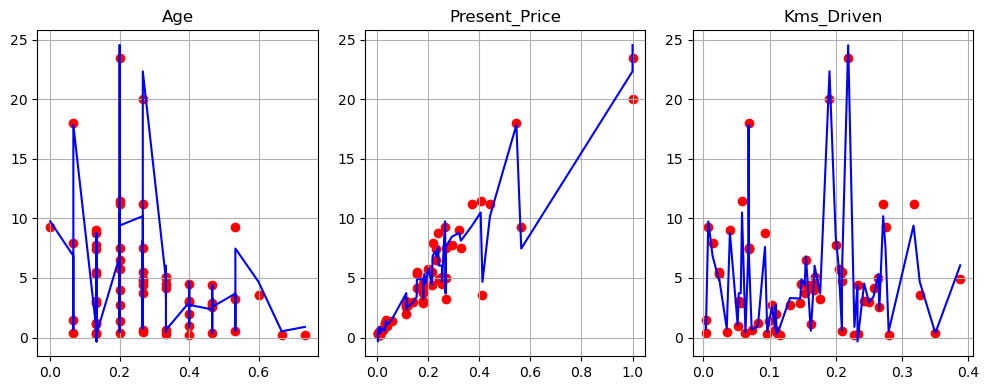

In [90]:
fig, axs = plt.subplots(1,3,sharex=False, figsize=(10, 4))
axs[0].plot(nx_test11.sort_values(by="Age")["Age"],nx_test11.sort_values(by="Age")["Y_Prediction"],color="Blue")
axs[0].scatter(nx_test11.sort_values(by="Age")["Age"],nx_test11.sort_values(by="Age")["Y_Test"],color="Red")
axs[0].grid();axs[0].set_title("Age")
axs[1].plot(nx_test11.sort_values(by="Present_Price")["Present_Price"],nx_test11.sort_values(by="Present_Price")["Y_Prediction"],color="Blue")
axs[1].scatter(nx_test11.sort_values(by="Present_Price")["Present_Price"],nx_test11.sort_values(by="Present_Price")["Y_Test"],color="Red")
axs[1].grid();axs[1].set_title("Present_Price")
axs[2].plot(nx_test11.sort_values(by="Kms_Driven")["Kms_Driven"],nx_test11.sort_values(by="Kms_Driven")["Y_Prediction"],color="Blue")
axs[2].scatter(nx_test11.sort_values(by="Kms_Driven")["Kms_Driven"],nx_test11.sort_values(by="Kms_Driven")["Y_Test"],color="Red")
axs[2].grid();axs[2].set_title("Kms_Driven");
fig.tight_layout()

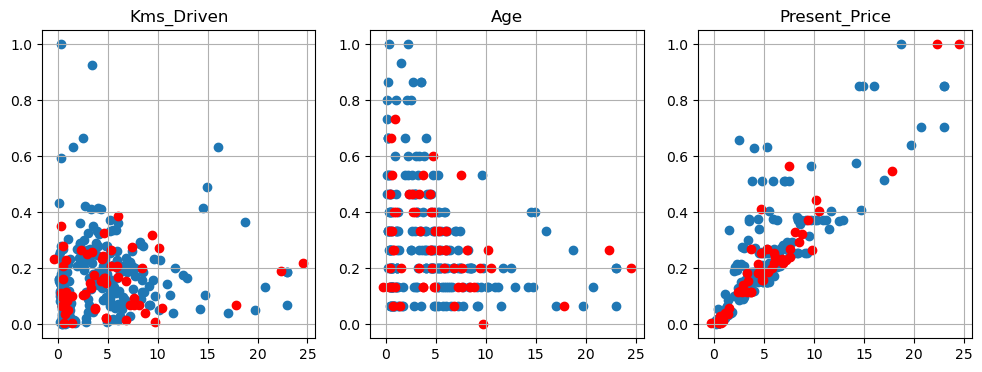

In [91]:
fig, axs = plt.subplots(1,3,sharex=False, figsize=(12, 4))
axs[1].scatter(y_train11,x_train11["Age"])
axs[1].scatter(y_pred11,x_test11["Age"],color="Red")
axs[1].grid();axs[1].set_title("Age")
axs[2].scatter(y_train11,x_train11["Present_Price"])
axs[2].scatter(y_pred11,x_test11["Present_Price"],color="Red")
axs[2].grid();axs[2].set_title("Present_Price")
axs[0].scatter(y_train11,x_train11["Kms_Driven"])
axs[0].scatter(y_pred11,x_test11["Kms_Driven"],color="Red")
axs[0].grid();axs[0].set_title("Kms_Driven");

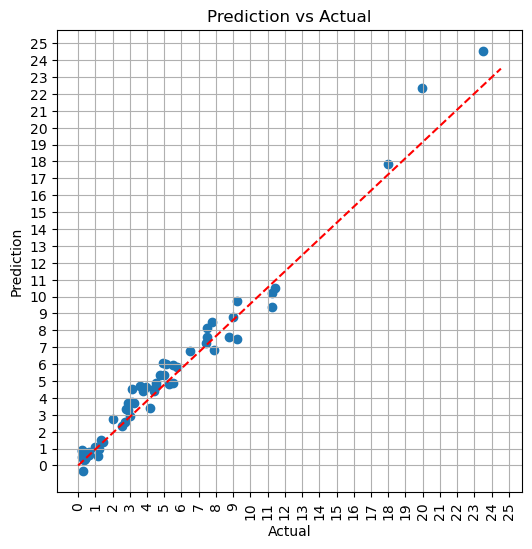

In [92]:
plt.figure(figsize=(6,6));plt.scatter(y_test11,y_pred11);plt.title("Prediction vs Actual");
plt.xticks(np.arange(0,np.max(y_pred11)+5),rotation=90);plt.yticks(np.arange(0,np.max(y_test11)+5));
plt.xlabel("Actual");plt.ylabel("Prediction");plt.grid();
plt.plot([0, np.max(y_pred11)], [0, np.max(y_test11)], ls="--", c="Red");

In [93]:
dfnu

,Age,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner,Selling_Price
0,5,5.59,27000,3.0,3.0,2.0,0,3.35
1,6,9.54,43000,2.0,3.0,2.0,0,4.75
2,2,9.85,6900,3.0,3.0,2.0,0,7.25
3,8,4.15,5200,3.0,3.0,2.0,0,2.85
4,5,6.87,42450,2.0,3.0,2.0,0,4.60
...,...,...,...,...,...,...,...,...
293,3,11.60,33988,2.0,3.0,2.0,0,9.50
294,4,5.90,60000,3.0,3.0,2.0,0,4.00
295,10,11.00,87934,3.0,3.0,2.0,0,3.35
296,2,12.50,9000,2.0,3.0,2.0,0,11.50


In [94]:
dfn11

,Age,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner,Age*Pres,Fue*Trans,Pres*Trans,Fue*Sel*Tran,Kms/Age,Selling_Price
0,5,5.59,27000,3.0,3.0,2.0,0,27.95,6.0,11.18,18.0,5400.000000,3.35
1,6,9.54,43000,2.0,3.0,2.0,0,57.24,4.0,19.08,12.0,7166.666667,4.75
2,2,9.85,6900,3.0,3.0,2.0,0,19.70,6.0,19.70,18.0,3450.000000,7.25
3,8,4.15,5200,3.0,3.0,2.0,0,33.20,6.0,8.30,18.0,650.000000,2.85
4,5,6.87,42450,2.0,3.0,2.0,0,34.35,4.0,13.74,12.0,8490.000000,4.60
...,...,...,...,...,...,...,...,...,...,...,...,...,...
293,3,11.60,33988,2.0,3.0,2.0,0,34.80,4.0,23.20,12.0,11329.333333,9.50
294,4,5.90,60000,3.0,3.0,2.0,0,23.60,6.0,11.80,18.0,15000.000000,4.00
295,10,11.00,87934,3.0,3.0,2.0,0,110.00,6.0,22.00,18.0,8793.400000,3.35
296,2,12.50,9000,2.0,3.0,2.0,0,25.00,4.0,25.00,12.0,4500.000000,11.50


<div style="border-radius:10px; padding: 10px; background-color: #C1E1C1; font-size:115%; text-align:left">
<font color=black>Creating 11th model equation.

In [95]:
print("y = {} + {}*(X1) + {}*(X2) + {}*(X3) + {}*(X4) + {}*(X5) + {}*(X6) + {}*(X7) + {}*(X1*X2) + {}*(X4*X6) + {}*(X4*X5*X6) + {}*(X3/X1)".
      format(np.round(regressor.intercept_[0],2),
             np.round(regressor.coef_[0][0],2),
             np.round(regressor.coef_[0][1],2),
             np.round(regressor.coef_[0][2],2),
             np.round(regressor.coef_[0][3],2),
             np.round(regressor.coef_[0][4],2),
             np.round(regressor.coef_[0][5],2),
             np.round(regressor.coef_[0][6],2),
             np.round(regressor.coef_[0][7],2),
             np.round(regressor.coef_[0][8],2),
             np.round(regressor.coef_[0][9],2),
             np.round(regressor.coef_[0][10],2)))

y = 3.25 + 0.54*(X1) + 33.26*(X2) + 0.79*(X3) + 2.34*(X4) + -1.17*(X5) + 4.28*(X6) + 1.01*(X7) + -20.93*(X1*X2) + -10.01*(X4*X6) + -2.68*(X4*X5*X6) + 4.58*(X3/X1)


<div style="border-radius:10px; padding: 10px; background-color: #C1E1C1; font-size:115%; text-align:left">
<font color=black>New entry that our model must predict

In [96]:
nd = {"Age":[8,5,1,13,6,2,12,10,10],"Present_Price":[8.75,10.35,17.85,25.25,13.14,10,24.24,18.85,11.23],
        "Kms_Driven":[7000,10000,13000,25000,20000,20000,20000,85000,42000],
        "Fuel_Type":["Petrol","Diesel","Petrol","Diesel","Petrol","Petrol","Petrol","Diesel","CNG"],
      "Seller_Type":["Individual","Dealer","Dealer","Individual","Individual","Dealer","Dealer","Dealer","Individual"],
        "Transmission":["Automatic","Manual","Automatic","Manual","Automatic","Automatic","Automatic","Manual","Manual"],"Owner":[2,3,2,4,3,1,3,2,2]}
df_t = pd.DataFrame(nd)

In [97]:
df_t

,Age,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,8,8.75,7000,Petrol,Individual,Automatic,2
1,5,10.35,10000,Diesel,Dealer,Manual,3
2,1,17.85,13000,Petrol,Dealer,Automatic,2
3,13,25.25,25000,Diesel,Individual,Manual,4
4,6,13.14,20000,Petrol,Individual,Automatic,3
5,2,10.00,20000,Petrol,Dealer,Automatic,1
6,12,24.24,20000,Petrol,Dealer,Automatic,3
7,10,18.85,85000,Diesel,Dealer,Manual,2
8,10,11.23,42000,CNG,Individual,Manual,2


In [98]:
df_t["Fuel_Type"] = df_t["Fuel_Type"].replace(["CNG","Petrol","Diesel"], [4.0,3.0,2.0])
df_t["Seller_Type"] = df_t["Seller_Type"].replace(["Dealer","Individual"], [3.0,2.0])
df_t["Transmission"] = df_t["Transmission"].replace(["Automatic","Manual"], [3.0,2.0])

df_t["Age*Pres"] = df_t["Age"]*df_t["Present_Price"]
df_t["Fue*Trans"] = df_t["Fuel_Type"]*df_t["Transmission"]
df_t["Pres*Trans"] = df_t["Present_Price"]*df_t["Transmission"]
df_t["Fue*Sel*Tran"] = df_t["Fuel_Type"]*df_t["Seller_Type"]*df_t["Transmission"]
df_t["Kms/Age"] = df_t["Kms_Driven"]/df_t["Age"]

df_t.head()

,Age,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner,Age*Pres,Fue*Trans,Pres*Trans,Fue*Sel*Tran,Kms/Age
0,8,8.75,7000,3.0,2.0,3.0,2,70.00,9.0,26.25,18.0,875.000000
1,5,10.35,10000,2.0,3.0,2.0,3,51.75,4.0,20.70,12.0,2000.000000
2,1,17.85,13000,3.0,3.0,3.0,2,17.85,9.0,53.55,27.0,13000.000000
3,13,25.25,25000,2.0,2.0,2.0,4,328.25,4.0,50.50,8.0,1923.076923
4,6,13.14,20000,3.0,2.0,3.0,3,78.84,9.0,39.42,18.0,3333.333333


<div style="border-radius:10px; padding: 10px; background-color: #C1E1C1; font-size:115%; text-align:left">
<font color=black>Scaling with the same scaler we used for the model. As you can see we only scale the entry not adding it to our data and scale it again.

In [99]:
Nt = scaler.fit_transform(df_t)
df_tw = pd.DataFrame(Nt,columns = list(df_t.columns))
df_tw

,Age,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner,Age*Pres,Fue*Trans,Pres*Trans,Fue*Sel*Tran,Kms/Age
0,0.583333,0.000000,0.000000,0.5,0.0,1.0,0.333333,0.168009,1.0,0.106690,0.526316,0.000000
1,0.333333,0.096970,0.038462,0.0,1.0,0.0,0.666667,0.109214,0.0,0.000000,0.210526,0.092784
2,0.000000,0.551515,0.076923,0.5,1.0,1.0,0.333333,0.000000,1.0,0.631488,1.000000,1.000000
3,1.000000,1.000000,0.230769,0.0,0.0,0.0,1.000000,1.000000,0.0,0.572857,0.000000,0.086439
4,0.416667,0.266061,0.166667,0.5,0.0,1.0,0.666667,0.196488,1.0,0.359862,0.526316,0.202749
5,0.083333,0.075758,0.166667,0.5,1.0,1.0,0.000000,0.006927,1.0,0.178777,1.000000,0.752577
6,0.916667,0.938788,0.166667,0.5,1.0,1.0,0.666667,0.879607,1.0,1.000000,1.000000,0.065292
7,0.750000,0.612121,1.000000,0.0,1.0,0.0,0.333333,0.549774,0.0,0.326797,0.210526,0.628866
8,0.750000,0.150303,0.448718,1.0,0.0,0.0,0.333333,0.304285,0.8,0.033833,0.421053,0.274227


In [100]:
df_testw = pd.concat([dfw11.drop(columns="Selling_Price"),df_tw],ignore_index=True)

In [101]:
xt = df_testw.iloc[:298,:]
yt = dfw11["Selling_Price"].values.reshape(-1,1)
regressor.fit(xt,yt)
y_predt = regressor.predict(df_testw.iloc[298:,:])

#to avoid negetive values since car prices can not be negetive
for i,j in enumerate(y_predt):
    if j[0]<=0:
        y_predt[i][0] = 0
        
dfx = dfn11.copy()
dfp = df_t.copy();dfp["Selling_Price"]=y_predt
df_tf = pd.concat([dfx,dfp],ignore_index=True)
df_tf.head()

,Age,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner,Age*Pres,Fue*Trans,Pres*Trans,Fue*Sel*Tran,Kms/Age,Selling_Price
0,5,5.59,27000,3.0,3.0,2.0,0,27.95,6.0,11.18,18.0,5400.000000,3.35
1,6,9.54,43000,2.0,3.0,2.0,0,57.24,4.0,19.08,12.0,7166.666667,4.75
2,2,9.85,6900,3.0,3.0,2.0,0,19.70,6.0,19.70,18.0,3450.000000,7.25
3,8,4.15,5200,3.0,3.0,2.0,0,33.20,6.0,8.30,18.0,650.000000,2.85
4,5,6.87,42450,2.0,3.0,2.0,0,34.35,4.0,13.74,12.0,8490.000000,4.60


In [102]:
dfp

,Age,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner,Age*Pres,Fue*Trans,Pres*Trans,Fue*Sel*Tran,Kms/Age,Selling_Price
0,8,8.75,7000,3.0,2.0,3.0,2,70.00,9.0,26.25,18.0,875.000000,0.000000
1,5,10.35,10000,2.0,3.0,2.0,3,51.75,4.0,20.70,12.0,2000.000000,5.001708
2,1,17.85,13000,3.0,3.0,3.0,2,17.85,9.0,53.55,27.0,13000.000000,17.056092
3,13,25.25,25000,2.0,2.0,2.0,4,328.25,4.0,50.50,8.0,1923.076923,16.857979
4,6,13.14,20000,3.0,2.0,3.0,3,78.84,9.0,39.42,18.0,3333.333333,5.192036
5,2,10.00,20000,3.0,3.0,3.0,1,20.00,9.0,30.00,27.0,10000.000000,2.734204
6,12,24.24,20000,3.0,3.0,3.0,3,290.88,9.0,72.72,27.0,1666.666667,12.651300
7,10,18.85,85000,2.0,3.0,2.0,2,188.50,4.0,37.70,12.0,8500.000000,12.238349
8,10,11.23,42000,4.0,2.0,2.0,2,112.30,8.0,22.46,16.0,4200.000000,0.000000


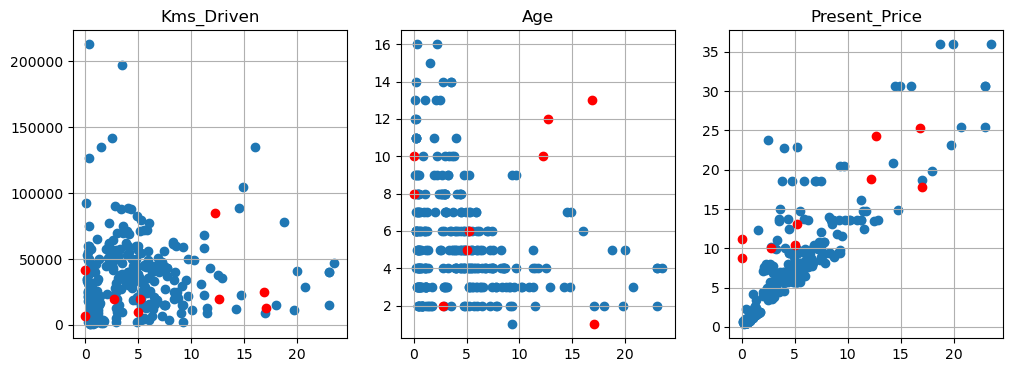

In [103]:
fig, axs = plt.subplots(1,3,sharex=False, figsize=(12, 4))
axs[1].scatter(dfx["Selling_Price"],dfx["Age"])
axs[1].scatter(dfp["Selling_Price"],dfp["Age"],color="Red")
axs[1].grid();axs[1].set_title("Age")
axs[2].scatter(dfx["Selling_Price"],dfx["Present_Price"])
axs[2].scatter(dfp["Selling_Price"],dfp["Present_Price"],color="Red")
axs[2].grid();axs[2].set_title("Present_Price")
axs[0].scatter(dfx["Selling_Price"],dfx["Kms_Driven"])
axs[0].scatter(dfp["Selling_Price"],dfp["Kms_Driven"],color="Red")
axs[0].grid();axs[0].set_title("Kms_Driven");